In [1]:
import pandas as pd
import numpy as np
import os

BASE_DIR = r"C:\Users\vikra\Desktop\Supply Chain Algo"

DATA_PATH = os.path.join(
    BASE_DIR,
    "Data",
    "processed",
    "sales_features.csv.gz"
)

df = pd.read_csv(
    DATA_PATH,
    compression="gzip"
)

df["date"] = pd.to_datetime(df["date"])

print("Dataset loaded successfully!")
print("Shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Shape: (2950992, 33)


,id,date,store_nbr,family,sales,onpromotion,city,state,type,cluster,...,month_cos,day_sin,day_cos,sales_lag_1,sales_lag_7,sales_lag_14,sales_lag_28,sales_rolling_mean_7,sales_rolling_mean_14,sales_rolling_mean_28
0,49896,2013-01-29,1,AUTOMOTIVE,2.0,0,Quito,Pichincha,D,13,...,0.866025,0.781831,0.623490,3.0,1.0,1.0,0.0,2.571429,2.142857,2.142857
1,51678,2013-01-30,1,AUTOMOTIVE,6.0,0,Quito,Pichincha,D,13,...,0.866025,0.974928,-0.222521,2.0,3.0,1.0,2.0,2.714286,2.214286,2.214286
2,53460,2013-01-31,1,AUTOMOTIVE,0.0,0,Quito,Pichincha,D,13,...,0.866025,0.433884,-0.900969,6.0,0.0,1.0,3.0,3.142857,2.571429,2.357143
3,55242,2013-02-01,1,AUTOMOTIVE,3.0,0,Quito,Pichincha,D,13,...,0.500000,-0.433884,-0.900969,0.0,5.0,0.0,3.0,3.142857,2.500000,2.250000
4,57024,2013-02-02,1,AUTOMOTIVE,0.0,0,Quito,Pichincha,D,13,...,0.500000,-0.974928,-0.222521,3.0,4.0,5.0,5.0,2.857143,2.714286,2.250000


In [2]:
print("Duplicate records:",
      df.duplicated(
          subset=["date", "store_nbr", "family"]
      ).sum())

print("\nDate range:")
print(df["date"].min(), "to", df["date"].max())

print("\nMissing target values:")
print(df["sales"].isnull().sum())

print("\nMissing lag features:")
display(
    df[
        [
            "sales_lag_1",
            "sales_lag_7",
            "sales_lag_14",
            "sales_lag_28"
        ]
    ].isnull().sum()
)

Duplicate records: 0

Date range:
2013-01-29 00:00:00 to 2017-08-15 00:00:00

Missing target values:
0

Missing lag features:


sales_lag_1     0
sales_lag_7     0
sales_lag_14    0
sales_lag_28    0
dtype: int64

In [3]:
# Sort by date
df = df.sort_values(
    ["date", "store_nbr", "family"]
).reset_index(drop=True)

# Select the last 16 days
last_date = df["date"].max()

validation_start = (
    last_date - pd.Timedelta(days=15)
)

train_df = df[
    df["date"] < validation_start
].copy()

valid_df = df[
    df["date"] >= validation_start
].copy()

print("Training period:")
print(train_df["date"].min(), "to", train_df["date"].max())

print("\nValidation period:")
print(valid_df["date"].min(), "to", valid_df["date"].max())

print("\nTraining shape:", train_df.shape)
print("Validation shape:", valid_df.shape)

print(
    "\nValidation days:",
    valid_df["date"].nunique()
)

Training period:
2013-01-29 00:00:00 to 2017-07-30 00:00:00

Validation period:
2017-07-31 00:00:00 to 2017-08-15 00:00:00

Training shape: (2922480, 33)
Validation shape: (28512, 33)

Validation days: 16


In [5]:
assert valid_df["date"].nunique() == 16, (
    "Validation must contain exactly 16 distinct dates."
)

assert train_df["date"].max() < valid_df["date"].min()

print("Chronological split validated!")

Chronological split validated!


In [6]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    mean_squared_log_error
)

y_true = valid_df["sales"].values

baseline_predictions = {
    "Previous Day": valid_df["sales_lag_1"].values,
    "Same Day Last Week": valid_df["sales_lag_7"].values,
    "7-Day Moving Average": valid_df["sales_rolling_mean_7"].values
}

In [7]:
def evaluate_model(y_true, y_pred, model_name):

    y_pred = np.maximum(y_pred, 0)
    y_true = np.maximum(y_true, 0)

    mae = mean_absolute_error(y_true, y_pred)

    rmse = np.sqrt(
        mean_squared_error(y_true, y_pred)
    )

    rmsle = np.sqrt(
        mean_squared_log_error(y_true, y_pred)
    )

    wape = (
        np.sum(np.abs(y_true - y_pred))
        / np.sum(y_true)
    ) * 100

    return {
        "Model": model_name,
        "MAE": mae,
        "RMSE": rmse,
        "RMSLE": rmsle,
        "WAPE (%)": wape
    }

In [8]:
baseline_results = []

for name, predictions in baseline_predictions.items():

    result = evaluate_model(
        y_true,
        predictions,
        name
    )

    baseline_results.append(result)

baseline_results_df = pd.DataFrame(
    baseline_results
)

display(
    baseline_results_df.sort_values("MAE")
)

,Model,MAE,RMSE,RMSLE,WAPE (%)
2,7-Day Moving Average,90.839535,297.306315,0.448937,19.445768
1,Same Day Last Week,100.230365,350.060513,0.569367,21.456037
0,Previous Day,112.703159,386.907178,0.546108,24.126054


### Random Forest

In [9]:
categorical_features = [
    "store_nbr",
    "family"
]

numeric_features = [
    "onpromotion",
    "has_holiday_event",
    "holiday_event_count",
    "year",
    "month",
    "day",
    "day_of_week",
    "day_of_year",
    "week_of_year",
    "quarter",
    "is_weekend",
    "month_sin",
    "month_cos",
    "day_sin",
    "day_cos",
    "sales_lag_1",
    "sales_lag_7",
    "sales_lag_14",
    "sales_lag_28",
    "sales_rolling_mean_7",
    "sales_rolling_mean_14",
    "sales_rolling_mean_28"
]

# Keep only columns present in the dataset
categorical_features = [
    col for col in categorical_features
    if col in df.columns
]

numeric_features = [
    col for col in numeric_features
    if col in df.columns
]

feature_columns = (
    categorical_features + numeric_features
)

print("Categorical features:", categorical_features)
print("Numerical features:", numeric_features)
print("Total features:", len(feature_columns))

Categorical features: ['store_nbr', 'family']
Numerical features: ['onpromotion', 'has_holiday_event', 'holiday_event_count', 'year', 'month', 'day', 'day_of_week', 'day_of_year', 'week_of_year', 'quarter', 'is_weekend', 'month_sin', 'month_cos', 'day_sin', 'day_cos', 'sales_lag_1', 'sales_lag_7', 'sales_lag_14', 'sales_lag_28', 'sales_rolling_mean_7', 'sales_rolling_mean_14', 'sales_rolling_mean_28']
Total features: 24


In [10]:
%pip install scikit-learn

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [11]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor

In [12]:
try:
    encoder = OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=True
    )
except TypeError:
    encoder = OneHotEncoder(
        handle_unknown="ignore",
        sparse=True
    )

In [13]:
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", encoder)
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

In [14]:
rf_model = Pipeline(steps=[
    ("preprocessor", preprocessor),

    ("regressor", RandomForestRegressor(
        n_estimators=100,
        max_depth=18,
        min_samples_leaf=5,
        max_features=0.8,
        n_jobs=-1,
        random_state=42
    ))
])

In [15]:
TRAIN_SAMPLE_SIZE = 100_000

train_sample = train_df.sample(
    n=min(TRAIN_SAMPLE_SIZE, len(train_df)),
    random_state=42
)

X_train_sample = train_sample[feature_columns].copy()

for col in categorical_features:
    X_train_sample[col] = X_train_sample[col].astype(str)

y_train_sample = train_sample["sales"].clip(lower=0)

# Log transformation helps manage highly skewed demand
y_train_log = np.log1p(y_train_sample)

print("Training Random Forest...")

rf_model.fit(
    X_train_sample,
    y_train_log
)

print("Random Forest training completed!")

Training Random Forest...
Random Forest training completed!


In [18]:
# Define categorical and numerical features
categorical_features = ["store_nbr", "family"]

numeric_features = [
    "onpromotion",
    "has_holiday_event",
    "holiday_event_count",
    "year",
    "month",
    "day",
    "day_of_week",
    "day_of_year",
    "week_of_year",
    "quarter",
    "is_weekend",
    "month_sin",
    "month_cos",
    "day_sin",
    "day_cos",
    "sales_lag_1",
    "sales_lag_7",
    "sales_lag_14",
    "sales_lag_28",
    "sales_rolling_mean_7",
    "sales_rolling_mean_14",
    "sales_rolling_mean_28"
]

# Keep available columns
categorical_features = [
    c for c in categorical_features if c in df.columns
]

numeric_features = [
    c for c in numeric_features if c in df.columns
]

feature_columns = categorical_features + numeric_features

# Recreate validation features
X_valid = valid_df[feature_columns].copy()

# Convert categorical columns to string
for col in categorical_features:
    X_valid[col] = X_valid[col].astype(str)

# Validation target
y_valid = valid_df["sales"].copy()

print("X_valid shape:", X_valid.shape)
print("y_valid shape:", y_valid.shape)

X_valid shape: (28512, 24)
y_valid shape: (28512,)


In [19]:
rf_predictions_log = rf_model.predict(X_valid)

rf_predictions = np.expm1(
    rf_predictions_log
)

rf_predictions = np.maximum(
    rf_predictions, 0
)

rf_result = evaluate_model(
    y_valid.values,
    rf_predictions,
    "Random Forest"
)

print(rf_result)

{'Model': 'Random Forest', 'MAE': 67.00954872132253, 'RMSE': np.float64(227.03723969271994), 'RMSLE': np.float64(0.40117624030953347), 'WAPE (%)': np.float64(14.344548872107424)}


In [20]:
all_results = baseline_results + [rf_result]

comparison_df = pd.DataFrame(all_results)

comparison_df = comparison_df.sort_values(
    by="MAE"
).reset_index(drop=True)

display(comparison_df)

,Model,MAE,RMSE,RMSLE,WAPE (%)
0,Random Forest,67.009549,227.037240,0.401176,14.344549
1,7-Day Moving Average,90.839535,297.306315,0.448937,19.445768
2,Same Day Last Week,100.230365,350.060513,0.569367,21.456037
3,Previous Day,112.703159,386.907178,0.546108,24.126054


In [21]:
import joblib

MODEL_DIR = os.path.join(BASE_DIR, "models")
REPORT_DIR = os.path.join(BASE_DIR, "reports")

os.makedirs(MODEL_DIR, exist_ok=True)
os.makedirs(REPORT_DIR, exist_ok=True)

joblib.dump(
    rf_model,
    os.path.join(
        MODEL_DIR,
        "random_forest_demand_model.joblib"
    )
)

comparison_df.to_csv(
    os.path.join(
        REPORT_DIR,
        "model_comparison.csv"
    ),
    index=False
)

print("Model saved successfully!")
print("Model comparison report saved!")

Model saved successfully!
Model comparison report saved!


In [22]:
%pip install xgboost

Defaulting to user installation because normal site-packages is not writeable
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.5/48.9 MB 5.4 MB/s eta 0:00:09
   --- ------------------------------------ 4.5/48.9 MB 15.7 MB/s eta 0:00:03
   ------- -------------------------------- 9.2/48.9 MB 19.5 MB/s eta 0:00:03
   ---------- ----------------------------- 12.3/48.9 MB 19.6 MB/s eta 0:00:02
   -------------- ------------------------- 17.3/48.9 MB 19.6 MB/s eta 0:00:02
   ----------------- ---------------------- 21.2/48.9 MB 20.6 MB/s eta 0:00:02
   ---------------------- ----------------- 27.8/48.9 MB 21.2 MB/s eta 0:00:02
   -------------------------- ------------- 32.2/48.9 MB 21.4 MB/s eta 0:00:01
   ------------------------------ --------- 37.2/48.9 MB 21.4 MB/s eta 0:00:01
   ---------------------------------- ----- 41.9/48.9 MB 21.6 MB/s eta 0:00:01
   -------------------------------------- - 46.7/48.9 MB 21.6 MB/s

In [23]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from xgboost import XGBRegressor


In [24]:
BASE_DIR = r"C:\Users\vikra\Desktop\Supply Chain Algo"

DATA_PATH = os.path.join(
    BASE_DIR,
    "Data",
    "processed",
    "sales_features.csv.gz"
)

df = pd.read_csv(DATA_PATH)

df["date"] = pd.to_datetime(df["date"])

print("Dataset Shape:", df.shape)
display(df.head())

Dataset Shape: (2950992, 33)


,id,date,store_nbr,family,sales,onpromotion,city,state,type,cluster,...,month_cos,day_sin,day_cos,sales_lag_1,sales_lag_7,sales_lag_14,sales_lag_28,sales_rolling_mean_7,sales_rolling_mean_14,sales_rolling_mean_28
0,49896,2013-01-29,1,AUTOMOTIVE,2.0,0,Quito,Pichincha,D,13,...,0.866025,0.781831,0.623490,3.0,1.0,1.0,0.0,2.571429,2.142857,2.142857
1,51678,2013-01-30,1,AUTOMOTIVE,6.0,0,Quito,Pichincha,D,13,...,0.866025,0.974928,-0.222521,2.0,3.0,1.0,2.0,2.714286,2.214286,2.214286
2,53460,2013-01-31,1,AUTOMOTIVE,0.0,0,Quito,Pichincha,D,13,...,0.866025,0.433884,-0.900969,6.0,0.0,1.0,3.0,3.142857,2.571429,2.357143
3,55242,2013-02-01,1,AUTOMOTIVE,3.0,0,Quito,Pichincha,D,13,...,0.500000,-0.433884,-0.900969,0.0,5.0,0.0,3.0,3.142857,2.500000,2.250000
4,57024,2013-02-02,1,AUTOMOTIVE,0.0,0,Quito,Pichincha,D,13,...,0.500000,-0.974928,-0.222521,3.0,4.0,5.0,5.0,2.857143,2.714286,2.250000


In [25]:
df = df.sort_values("date").reset_index(drop=True)

last_date = df["date"].max()

validation_start = last_date - pd.Timedelta(days=15)

train_df = df[
    df["date"] < validation_start
].copy()

valid_df = df[
    df["date"] >= validation_start
].copy()

print("Training Shape:", train_df.shape)
print("Validation Shape:", valid_df.shape)

print("Training Dates:",
      train_df["date"].min(),
      "to",
      train_df["date"].max())

print("Validation Dates:",
      valid_df["date"].min(),
      "to",
      valid_df["date"].max())

print("Validation Days:", valid_df["date"].nunique())

Training Shape: (2922480, 33)
Validation Shape: (28512, 33)
Training Dates: 2013-01-29 00:00:00 to 2017-07-30 00:00:00
Validation Dates: 2017-07-31 00:00:00 to 2017-08-15 00:00:00
Validation Days: 16


In [26]:
categorical_features = [
    "store_nbr",
    "family"
]

numeric_features = [
    "onpromotion",
    "has_holiday_event",
    "holiday_event_count",
    "year",
    "month",
    "day",
    "day_of_week",
    "day_of_year",
    "week_of_year",
    "quarter",
    "is_weekend",
    "month_sin",
    "month_cos",
    "day_sin",
    "day_cos",
    "sales_lag_1",
    "sales_lag_7",
    "sales_lag_14",
    "sales_lag_28",
    "sales_rolling_mean_7",
    "sales_rolling_mean_14",
    "sales_rolling_mean_28"
]

categorical_features = [
    col for col in categorical_features
    if col in df.columns
]

numeric_features = [
    col for col in numeric_features
    if col in df.columns
]

feature_columns = categorical_features + numeric_features

X_train = train_df[feature_columns].copy()
X_valid = valid_df[feature_columns].copy()

y_train = train_df["sales"].clip(lower=0)
y_valid = valid_df["sales"].clip(lower=0)

# Use 100,000 training records to manage memory
train_sample = train_df.sample(
    n=min(100_000, len(train_df)),
    random_state=42
)

X_train_sample = train_sample[feature_columns].copy()

y_train_sample = np.log1p(
    train_sample["sales"].clip(lower=0)
)

for col in categorical_features:
    X_train_sample[col] = X_train_sample[col].astype(str)
    X_valid[col] = X_valid[col].astype(str)

print("Training sample:", X_train_sample.shape)
print("Validation data:", X_valid.shape)

Training sample: (100000, 24)
Validation data: (28512, 24)


In [27]:
try:
    encoder = OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=True
    )
except TypeError:
    encoder = OneHotEncoder(
        handle_unknown="ignore",
        sparse=True
    )

numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", encoder)
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

In [31]:
print("XGBoost training started...")

xgb_model.fit(
    X_train_sample,
    y_train_sample
)

print("XGBoost training completed successfully!")

XGBoost training started...
XGBoost training completed successfully!


In [28]:
xgb_model = Pipeline([
    ("preprocessor", preprocessor),

    ("regressor", XGBRegressor(
        n_estimators=400,
        learning_rate=0.05,
        max_depth=8,
        min_child_weight=5,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="reg:squarederror",
        tree_method="hist",
        n_jobs=-1,
        random_state=42
    ))
])

print("XGBoost model created!")

XGBoost model created!


In [29]:
xgb_model = Pipeline([
    ("preprocessor", preprocessor),

    ("regressor", XGBRegressor(
        n_estimators=400,
        learning_rate=0.05,
        max_depth=8,
        min_child_weight=5,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="reg:squarederror",
        tree_method="hist",
        n_jobs=-1,
        random_state=42
    ))
])

print("XGBoost model created!")

XGBoost model created!


In [32]:
xgb_predictions_log = xgb_model.predict(X_valid)

# Convert log predictions back to sales
xgb_predictions = np.expm1(
    xgb_predictions_log
)

xgb_predictions = np.maximum(
    xgb_predictions,
    0
)

print("Predictions completed!")
print("Total predictions:", len(xgb_predictions))

Predictions completed!
Total predictions: 28512


In [33]:
xgb_result = evaluate_model(
    y_valid,
    xgb_predictions,
    "XGBoost"
)

print(xgb_result)

{'Model': 'XGBoost', 'MAE': 65.6478456811125, 'RMSE': np.float64(226.90937590684), 'RMSLE': np.float64(0.3922632219626465), 'WAPE (%)': np.float64(14.053052866204988)}


In [34]:
import joblib
import os

MODEL_DIR = os.path.join(BASE_DIR, "models")
os.makedirs(MODEL_DIR, exist_ok=True)

joblib.dump(
    xgb_model,
    os.path.join(MODEL_DIR, "xgboost_demand_model.joblib")
)

print("Trained XGBoost model saved successfully!")

Trained XGBoost model saved successfully!


In [35]:
%pip install lightgbm

Defaulting to user installation because normal site-packages is not writeable
   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   --------------- ------------------------ 0.5/1.4 MB 4.1 MB/s eta 0:00:01
   ---------------------------------------- 1.4/1.4 MB 5.3 MB/s  0:00:00
Note: you may need to restart the kernel to use updated packages.


In [37]:
from lightgbm import LGBMRegressor
import lightgbm as lgb
print("LightGBM Version:", lgb.__version__)

LightGBM Version: 4.7.0


In [38]:
# Recreate chronological split if necessary

last_date = df["date"].max()

validation_start = last_date - pd.Timedelta(days=15)

train_df = df[
    df["date"] < validation_start
].copy()

valid_df = df[
    df["date"] >= validation_start
].copy()

# Training sample
train_sample = train_df.sample(
    n=min(100_000, len(train_df)),
    random_state=42
)

In [39]:
categorical_features = ["store_nbr", "family"]

numeric_features = [
    "onpromotion",
    "has_holiday_event",
    "holiday_event_count",
    "year",
    "month",
    "day",
    "day_of_week",
    "day_of_year",
    "week_of_year",
    "quarter",
    "is_weekend",
    "month_sin",
    "month_cos",
    "day_sin",
    "day_cos",
    "sales_lag_1",
    "sales_lag_7",
    "sales_lag_14",
    "sales_lag_28",
    "sales_rolling_mean_7",
    "sales_rolling_mean_14",
    "sales_rolling_mean_28"
]

categorical_features = [
    c for c in categorical_features if c in df.columns
]

numeric_features = [
    c for c in numeric_features if c in df.columns
]

feature_columns = categorical_features + numeric_features

X_train_sample = train_sample[feature_columns].copy()
X_valid = valid_df[feature_columns].copy()

y_train_sample = np.log1p(
    train_sample["sales"].clip(lower=0)
)

y_valid = valid_df["sales"].clip(lower=0)

for col in categorical_features:
    X_train_sample[col] = X_train_sample[col].astype(str)
    X_valid[col] = X_valid[col].astype(str)

print("Training Shape:", X_train_sample.shape)
print("Validation Shape:", X_valid.shape)

Training Shape: (100000, 24)
Validation Shape: (28512, 24)


In [40]:
lgbm_model = Pipeline([
    ("preprocessor", preprocessor),

    ("regressor", LGBMRegressor(
        n_estimators=500,
        learning_rate=0.05,
        num_leaves=31,
        max_depth=-1,
        min_child_samples=30,
        subsample=0.8,
        subsample_freq=1,
        colsample_bytree=0.8,
        reg_lambda=1,
        objective="regression",
        n_jobs=-1,
        random_state=42,
        verbosity=-1
    ))
])

print("LightGBM model created!")

LightGBM model created!


In [41]:
print("LightGBM training started...")

lgbm_model.fit(
    X_train_sample,
    y_train_sample
)

print("LightGBM training completed successfully!")

LightGBM training started...
LightGBM training completed successfully!


In [42]:
lgbm_predictions_log = lgbm_model.predict(X_valid)

# Convert logarithmic predictions to actual sales
lgbm_predictions = np.expm1(
    lgbm_predictions_log
)

# Sales cannot be negative
lgbm_predictions = np.maximum(
    lgbm_predictions,
    0
)

print("Predictions completed!")
print("Total predictions:", len(lgbm_predictions))

Predictions completed!
Total predictions: 28512


In [43]:
lgbm_result = evaluate_model(
    y_valid,
    lgbm_predictions,
    "LightGBM"
)

print(lgbm_result)

{'Model': 'LightGBM', 'MAE': 64.91134037019388, 'RMSE': np.float64(217.47771088615306), 'RMSLE': np.float64(0.39087907840630715), 'WAPE (%)': np.float64(13.895391210088254)}


In [45]:
all_results = []

# Add baseline models if available
if "baseline_results" in globals():
    all_results.extend(baseline_results)

# Add individual ML models if available
for result_name in [
    "rf_result",
    "xgb_result",
    "lgbm_result"
]:
    if result_name in globals():
        all_results.append(globals()[result_name])

comparison_df = pd.DataFrame(all_results)

comparison_df = comparison_df.sort_values(
    by="WAPE (%)"
).reset_index(drop=True)

display(comparison_df)

,Model,MAE,RMSE,RMSLE,WAPE (%)
0,LightGBM,64.911340,217.477711,0.390879,13.895391
1,XGBoost,65.647846,226.909376,0.392263,14.053053
2,Random Forest,67.009549,227.037240,0.401176,14.344549
3,7-Day Moving Average,90.839535,297.306315,0.448937,19.445768
4,Same Day Last Week,100.230365,350.060513,0.569367,21.456037
5,Previous Day,112.703159,386.907178,0.546108,24.126054


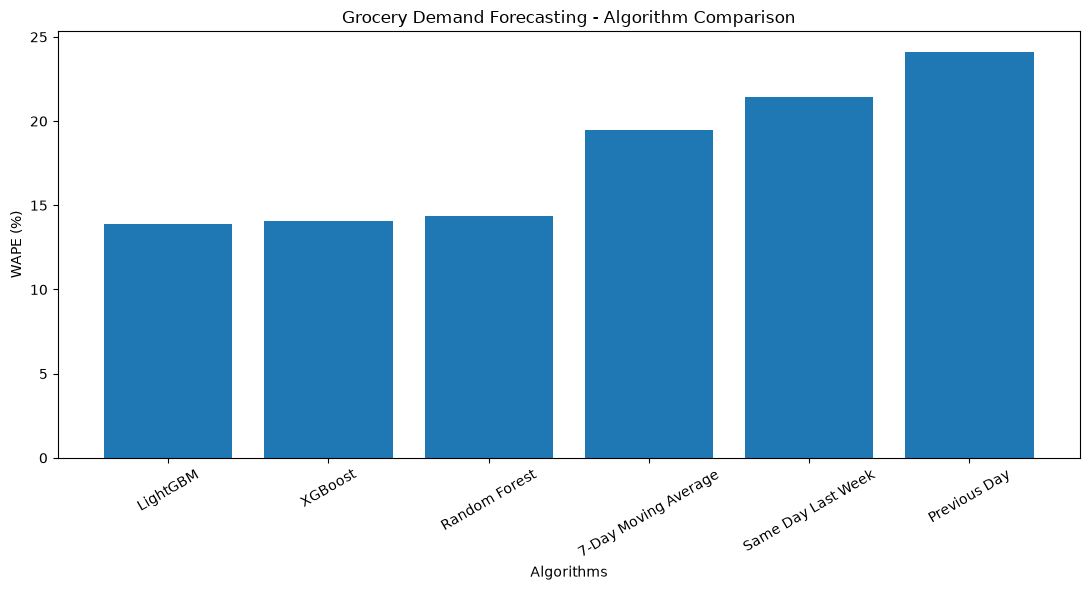

In [46]:
import matplotlib.pyplot as plt

plt.figure(figsize=(11, 6))

plt.bar(
    comparison_df["Model"],
    comparison_df["WAPE (%)"]
)

plt.title("Grocery Demand Forecasting - Algorithm Comparison")
plt.xlabel("Algorithms")
plt.ylabel("WAPE (%)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [47]:
fitted_preprocessor = lgbm_model.named_steps["preprocessor"]

fitted_regressor = lgbm_model.named_steps["regressor"]

feature_names = fitted_preprocessor.get_feature_names_out()

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": fitted_regressor.feature_importances_
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

display(importance_df.head(20))

,Feature,Importance
19,num__sales_rolling_mean_7,1414
7,num__day_of_year,1287
15,num__sales_lag_1,1168
16,num__sales_lag_7,1079
5,num__day,1049
21,num__sales_rolling_mean_28,1043
17,num__sales_lag_14,1018
20,num__sales_rolling_mean_14,902
18,num__sales_lag_28,860
6,num__day_of_week,762


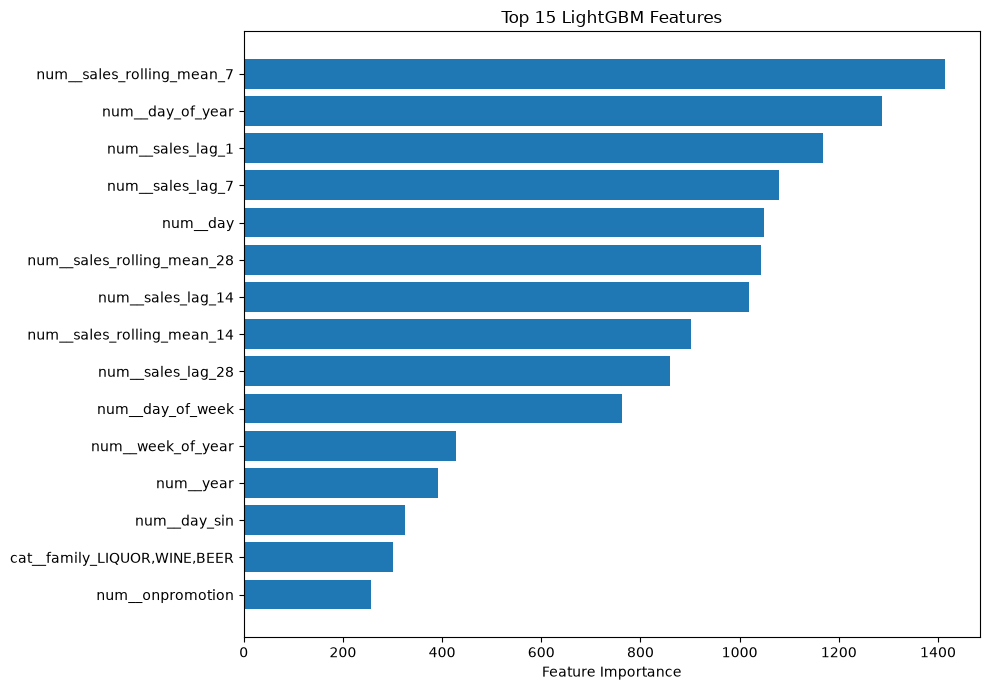

In [48]:
top_features = importance_df.head(15).sort_values(
    by="Importance"
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.title("Top 15 LightGBM Features")
plt.xlabel("Feature Importance")
plt.tight_layout()
plt.show()

In [49]:
BASE_DIR = r"C:\Users\vikra\Desktop\Supply Chain Algo"

MODEL_DIR = os.path.join(BASE_DIR, "models")
REPORT_DIR = os.path.join(BASE_DIR, "reports")

os.makedirs(MODEL_DIR, exist_ok=True)
os.makedirs(REPORT_DIR, exist_ok=True)

joblib.dump(
    lgbm_model,
    os.path.join(
        MODEL_DIR,
        "lightgbm_demand_model.joblib"
    )
)

comparison_df.to_csv(
    os.path.join(
        REPORT_DIR,
        "algorithm_comparison.csv"
    ),
    index=False
)

print("LightGBM model saved successfully!")
print("Model comparison report saved!")

LightGBM model saved successfully!
Model comparison report saved!


In [50]:
%pip install catboost

Defaulting to user installation because normal site-packages is not writeable
   ---------------------------------------- 0.0/101.7 MB ? eta -:--:--
   ---------------------------------------- 0.0/101.7 MB ? eta -:--:--
   ---------------------------------------- 0.0/101.7 MB ? eta -:--:--
   ---------------------------------------- 0.0/101.7 MB ? eta -:--:--
   ---------------------------------------- 0.3/101.7 MB ? eta -:--:--
   ---------------------------------------- 1.0/101.7 MB 2.0 MB/s eta 0:00:51
    --------------------------------------- 2.1/101.7 MB 3.1 MB/s eta 0:00:33
   - -------------------------------------- 4.5/101.7 MB 5.2 MB/s eta 0:00:19
   --- ------------------------------------ 9.4/101.7 MB 8.9 MB/s eta 0:00:11
   ------ --------------------------------- 17.6/101.7 MB 14.1 MB/s eta 0:00:06
   --------- ------------------------------ 25.2/101.7 MB 17.5 MB/s eta 0:00:05
   ---------- ----------------------------- 26.2/101.7 MB 17.1 MB/s eta 0:00:05
   ---------- -

In [51]:
import pandas as pd
import numpy as np
import catboost

from catboost import CatBoostRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    mean_squared_log_error
)

import os
import joblib

print("CatBoost Version:", catboost.__version__)

CatBoost Version: 1.2.10


In [52]:
BASE_DIR = r"C:\Users\vikra\Desktop\Supply Chain Algo"

DATA_PATH = os.path.join(
    BASE_DIR,
    "Data",
    "processed",
    "sales_features.csv.gz"
)

df = pd.read_csv(DATA_PATH)

df["date"] = pd.to_datetime(df["date"])

print("Dataset Shape:", df.shape)
display(df.head())

Dataset Shape: (2950992, 33)


,id,date,store_nbr,family,sales,onpromotion,city,state,type,cluster,...,month_cos,day_sin,day_cos,sales_lag_1,sales_lag_7,sales_lag_14,sales_lag_28,sales_rolling_mean_7,sales_rolling_mean_14,sales_rolling_mean_28
0,49896,2013-01-29,1,AUTOMOTIVE,2.0,0,Quito,Pichincha,D,13,...,0.866025,0.781831,0.623490,3.0,1.0,1.0,0.0,2.571429,2.142857,2.142857
1,51678,2013-01-30,1,AUTOMOTIVE,6.0,0,Quito,Pichincha,D,13,...,0.866025,0.974928,-0.222521,2.0,3.0,1.0,2.0,2.714286,2.214286,2.214286
2,53460,2013-01-31,1,AUTOMOTIVE,0.0,0,Quito,Pichincha,D,13,...,0.866025,0.433884,-0.900969,6.0,0.0,1.0,3.0,3.142857,2.571429,2.357143
3,55242,2013-02-01,1,AUTOMOTIVE,3.0,0,Quito,Pichincha,D,13,...,0.500000,-0.433884,-0.900969,0.0,5.0,0.0,3.0,3.142857,2.500000,2.250000
4,57024,2013-02-02,1,AUTOMOTIVE,0.0,0,Quito,Pichincha,D,13,...,0.500000,-0.974928,-0.222521,3.0,4.0,5.0,5.0,2.857143,2.714286,2.250000


In [53]:
df = df.sort_values("date").reset_index(drop=True)

last_date = df["date"].max()

validation_start = last_date - pd.Timedelta(days=15)

train_df = df[
    df["date"] < validation_start
].copy()

valid_df = df[
    df["date"] >= validation_start
].copy()

print("Training Shape:", train_df.shape)
print("Validation Shape:", valid_df.shape)

print("Validation Days:", valid_df["date"].nunique())

Training Shape: (2922480, 33)
Validation Shape: (28512, 33)
Validation Days: 16


In [54]:
categorical_features = [
    "store_nbr",
    "family"
]

numeric_features = [
    "onpromotion",
    "has_holiday_event",
    "holiday_event_count",
    "year",
    "month",
    "day",
    "day_of_week",
    "day_of_year",
    "week_of_year",
    "quarter",
    "is_weekend",
    "month_sin",
    "month_cos",
    "day_sin",
    "day_cos",
    "sales_lag_1",
    "sales_lag_7",
    "sales_lag_14",
    "sales_lag_28",
    "sales_rolling_mean_7",
    "sales_rolling_mean_14",
    "sales_rolling_mean_28"
]

categorical_features = [
    col for col in categorical_features
    if col in df.columns
]

numeric_features = [
    col for col in numeric_features
    if col in df.columns
]

feature_columns = categorical_features + numeric_features

print("Total Features:", len(feature_columns))
print(feature_columns)

Total Features: 24
['store_nbr', 'family', 'onpromotion', 'has_holiday_event', 'holiday_event_count', 'year', 'month', 'day', 'day_of_week', 'day_of_year', 'week_of_year', 'quarter', 'is_weekend', 'month_sin', 'month_cos', 'day_sin', 'day_cos', 'sales_lag_1', 'sales_lag_7', 'sales_lag_14', 'sales_lag_28', 'sales_rolling_mean_7', 'sales_rolling_mean_14', 'sales_rolling_mean_28']


In [55]:
train_sample = train_df.sample(
    n=min(100_000, len(train_df)),
    random_state=42
)

X_train = train_sample[feature_columns].copy()

X_valid = valid_df[feature_columns].copy()

y_train = np.log1p(
    train_sample["sales"].clip(lower=0)
)

y_valid = valid_df["sales"].clip(lower=0)

# CatBoost requires categorical values in a supported categorical format
for col in categorical_features:

    X_train[col] = (
        X_train[col]
        .fillna("Unknown")
        .astype(str)
    )

    X_valid[col] = (
        X_valid[col]
        .fillna("Unknown")
        .astype(str)
    )

print("Training Shape:", X_train.shape)
print("Validation Shape:", X_valid.shape)

Training Shape: (100000, 24)
Validation Shape: (28512, 24)


In [56]:
cat_model = CatBoostRegressor(
    iterations=600,
    learning_rate=0.05,
    depth=8,
    loss_function="RMSE",
    eval_metric="RMSE",
    l2_leaf_reg=5,
    random_seed=42,
    verbose=100,
    thread_count=-1,
    allow_writing_files=False
)

print("CatBoost model created successfully!")

CatBoost model created successfully!


In [57]:
print("CatBoost training started...")

cat_model.fit(
    X_train,
    y_train,
    cat_features=categorical_features
)

print("CatBoost training completed!")

CatBoost training started...
0:	learn: 2.5699199	total: 298ms	remaining: 2m 58s
100:	learn: 0.4239863	total: 12s	remaining: 59.4s
200:	learn: 0.4029616	total: 23.8s	remaining: 47.3s
300:	learn: 0.3912520	total: 35.2s	remaining: 34.9s
400:	learn: 0.3839380	total: 46.9s	remaining: 23.3s
500:	learn: 0.3778718	total: 58.6s	remaining: 11.6s
599:	learn: 0.3733300	total: 1m 10s	remaining: 0us
CatBoost training completed!


In [58]:
cat_predictions_log = cat_model.predict(X_valid)

cat_predictions = np.expm1(
    cat_predictions_log
)

cat_predictions = np.maximum(
    cat_predictions,
    0
)

print("Predictions completed!")
print("Total predictions:", len(cat_predictions))

Predictions completed!
Total predictions: 28512


In [59]:
def evaluate_model(y_true, y_pred, model_name):

    y_true = np.maximum(np.asarray(y_true), 0)
    y_pred = np.maximum(np.asarray(y_pred), 0)

    mae = mean_absolute_error(y_true, y_pred)

    rmse = np.sqrt(
        mean_squared_error(y_true, y_pred)
    )

    rmsle = np.sqrt(
        mean_squared_log_error(y_true, y_pred)
    )

    wape = (
        np.sum(np.abs(y_true - y_pred))
        / max(np.sum(y_true), 1e-10)
    ) * 100

    return {
        "Model": model_name,
        "MAE": mae,
        "RMSE": rmse,
        "RMSLE": rmsle,
        "WAPE (%)": wape
    }

In [60]:
cat_result = evaluate_model(
    y_valid,
    cat_predictions,
    "CatBoost"
)

print(cat_result)

{'Model': 'CatBoost', 'MAE': 67.67305212941933, 'RMSE': np.float64(226.93472705491982), 'RMSLE': np.float64(0.3935290428474371), 'WAPE (%)': np.float64(14.486583212673365)}


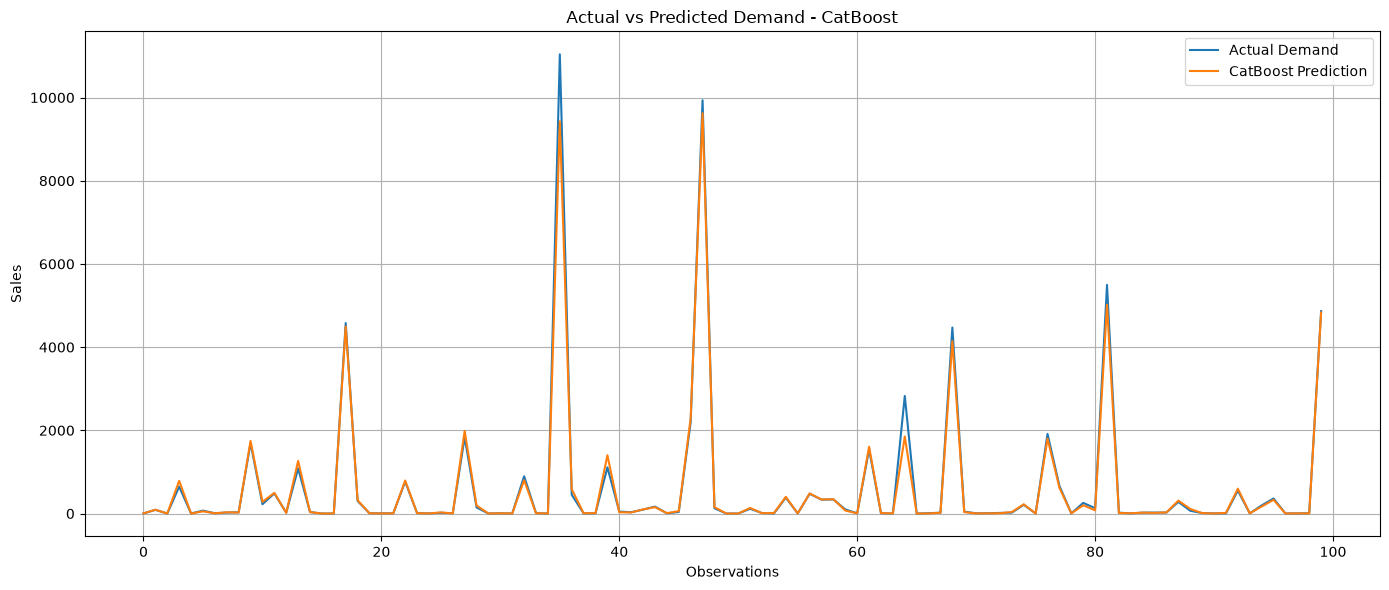

In [61]:
import matplotlib.pyplot as plt

comparison = pd.DataFrame({
    "Actual": y_valid.values,
    "Predicted": cat_predictions
})

plt.figure(figsize=(14, 6))

plt.plot(
    comparison["Actual"].head(100),
    label="Actual Demand"
)

plt.plot(
    comparison["Predicted"].head(100),
    label="CatBoost Prediction"
)

plt.title("Actual vs Predicted Demand - CatBoost")
plt.xlabel("Observations")
plt.ylabel("Sales")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [62]:
importance_df = pd.DataFrame({
    "Feature": feature_columns,
    "Importance": cat_model.get_feature_importance()
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

display(importance_df.head(20))

,Feature,Importance
21,sales_rolling_mean_7,21.513897
17,sales_lag_1,18.389358
18,sales_lag_7,14.129596
22,sales_rolling_mean_14,13.254918
19,sales_lag_14,7.756665
9,day_of_year,5.789361
23,sales_rolling_mean_28,4.653386
20,sales_lag_28,4.185792
1,family,2.980430
8,day_of_week,1.323785


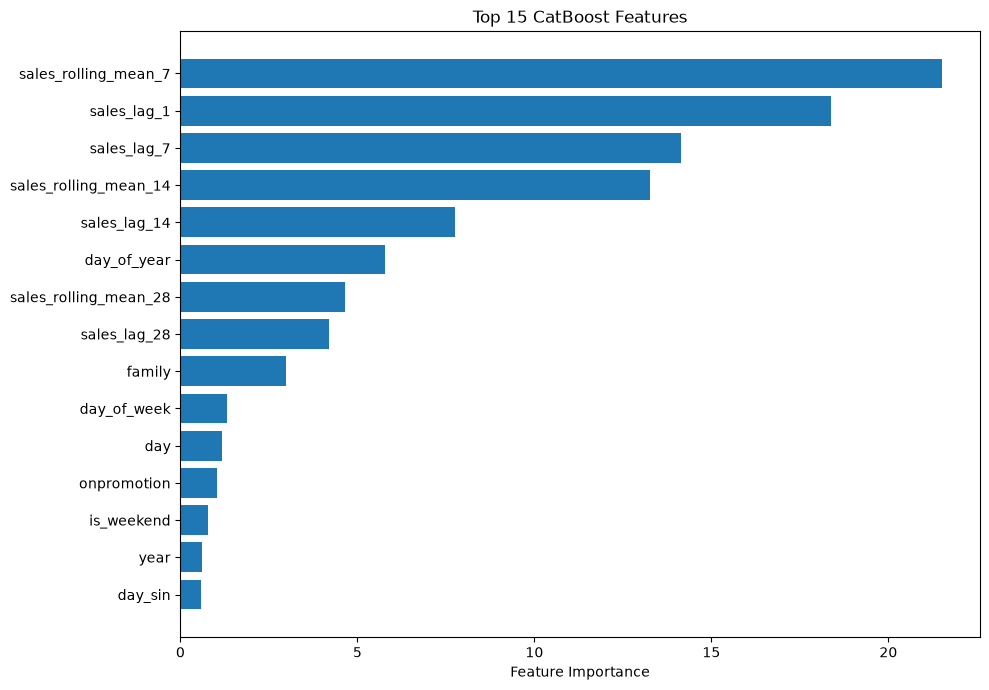

In [63]:
top_features = importance_df.head(15).sort_values(
    by="Importance"
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.title("Top 15 CatBoost Features")
plt.xlabel("Feature Importance")
plt.tight_layout()
plt.show()

In [64]:
MODEL_DIR = os.path.join(BASE_DIR, "models")
REPORT_DIR = os.path.join(BASE_DIR, "reports")

os.makedirs(MODEL_DIR, exist_ok=True)
os.makedirs(REPORT_DIR, exist_ok=True)

cat_model.save_model(
    os.path.join(
        MODEL_DIR,
        "catboost_demand_model.cbm"
    )
)

print("CatBoost model saved successfully!")

CatBoost model saved successfully!


In [65]:
pd.DataFrame([cat_result]).to_csv(
    os.path.join(
        REPORT_DIR,
        "catboost_evaluation.csv"
    ),
    index=False
)

print("Evaluation report saved!")

Evaluation report saved!


In [66]:
results = []

for name in [
    "rf_result",
    "xgb_result",
    "lgbm_result",
    "cat_result"
]:
    result = globals().get(name)

    if isinstance(result, dict):
        results.append(result)

if isinstance(globals().get("baseline_results"), list):
    results.extend(baseline_results)

comparison_df = pd.DataFrame(results)

comparison_df = comparison_df.sort_values(
    by="WAPE (%)"
).reset_index(drop=True)

display(comparison_df)

,Model,MAE,RMSE,RMSLE,WAPE (%)
0,LightGBM,64.911340,217.477711,0.390879,13.895391
1,XGBoost,65.647846,226.909376,0.392263,14.053053
2,Random Forest,67.009549,227.037240,0.401176,14.344549
3,CatBoost,67.673052,226.934727,0.393529,14.486583
4,7-Day Moving Average,90.839535,297.306315,0.448937,19.445768
5,Same Day Last Week,100.230365,350.060513,0.569367,21.456037
6,Previous Day,112.703159,386.907178,0.546108,24.126054


In [67]:
comparison_df.to_csv(
    os.path.join(
        REPORT_DIR,
        "final_algorithm_comparison.csv"
    ),
    index=False
)

print("Final comparison report saved!")

Final comparison report saved!
